Week 3 Notebook for Milestone 1

Last week, regularization showed that a simpler model predicts poor mental health days about as well as the full one. This week I test that more directly. Forward and backward selection pick the smallest useful set of the original 14 features. PCR and PLSR compress all features into a few combined components. Every model is tuned with 5-fold cross-validation and compared on the same held-out test set.

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

cols = ['MENTHLTH','PHYSHLTH','INCOME3','EMPLOY1','_HLTHPL2','MEDCOST1','GENHLTH','_AGE_G','_BMI5']
brfss = pd.read_sas('LLCP2024.XPT ', format='xport')[cols]

for c in ['MENTHLTH', 'PHYSHLTH']:
    brfss[c] = brfss[c].replace({88: 0, 77: np.nan, 99: np.nan})
brfss['INCOME3'] = brfss['INCOME3'].where(brfss['INCOME3'].between(1, 11))
brfss['GENHLTH'] = brfss['GENHLTH'].where(brfss['GENHLTH'].between(1, 5))
brfss['NO_INSURANCE'] = brfss['_HLTHPL2'].map({1: 0, 2: 1})
brfss['COST_BARRIER'] = brfss['MEDCOST1'].map({1: 1, 2: 0})
brfss['EMPLOY'] = brfss['EMPLOY1'].map({1: 'Employed', 2: 'SelfEmployed', 3: 'OutOfWork1yr+',
                                       4: 'OutOfWork<1yr', 5: 'Homemaker', 6: 'Student',
                                       7: 'Retired', 8: 'UnableToWork'})
brfss['BMI'] = brfss['_BMI5'] / 100
brfss = brfss.rename(columns={'_AGE_G': 'AGE_G'})

brfss = (brfss[['MENTHLTH','PHYSHLTH','INCOME3','GENHLTH','AGE_G','BMI',
                'NO_INSURANCE','COST_BARRIER','EMPLOY']]
         .dropna().sample(50_000, random_state=42).reset_index(drop=True))
brfss = pd.get_dummies(brfss, columns=['EMPLOY'], drop_first=True, dtype=int)

X, y = brfss.drop(columns='MENTHLTH'), brfss['MENTHLTH']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
cv = KFold(5, shuffle=True, random_state=42)
print(X.shape[1], 'features')

14 features


FORWARD (order added):
 k                added  cv_R2
 1             PHYSHLTH 0.1083
 2                AGE_G 0.1521
 3              GENHLTH 0.1803
 4         COST_BARRIER 0.1959
 5  EMPLOY_UnableToWork 0.2018
 6              INCOME3 0.2036
 7         NO_INSURANCE 0.2046
 8 EMPLOY_OutOfWork1yr+ 0.2055
 9 EMPLOY_OutOfWork<1yr 0.2060
10       EMPLOY_Retired 0.2063
11  EMPLOY_SelfEmployed 0.2065
12     EMPLOY_Homemaker 0.2065
13       EMPLOY_Student 0.2064
14                  BMI 0.2064

BACKWARD (order removed):
 k              removed  cv_R2
14                    - 0.2064
13                  BMI 0.2064
12       EMPLOY_Student 0.2065
11     EMPLOY_Homemaker 0.2065
10  EMPLOY_SelfEmployed 0.2063
 9       EMPLOY_Retired 0.2060
 8 EMPLOY_OutOfWork<1yr 0.2055
 7 EMPLOY_OutOfWork1yr+ 0.2046
 6         NO_INSURANCE 0.2036
 5              INCOME3 0.2018
 4  EMPLOY_UnableToWork 0.1959
 3         COST_BARRIER 0.1803
 2              GENHLTH 0.1521
 1                AGE_G 0.1083


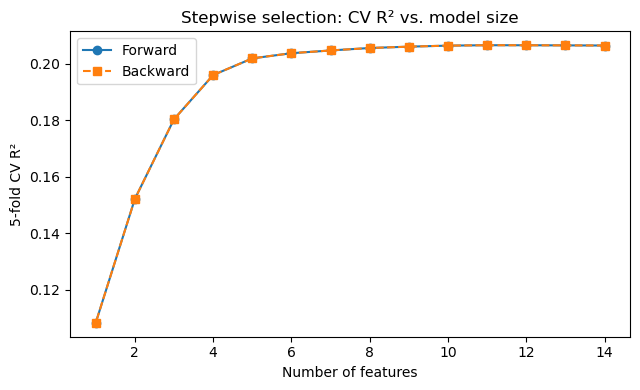

In [3]:
def cv_r2(feats):
    return cross_val_score(LinearRegression(), X_tr[feats], y_tr, cv=cv, scoring='r2').mean()

remaining, chosen, fwd = list(X_tr.columns), [], []
while remaining:
    scores = {f: cv_r2(chosen + [f]) for f in remaining}
    best = max(scores, key=scores.get)
    chosen.append(best); remaining.remove(best)
    fwd.append({'k': len(chosen), 'added': best, 'cv_R2': scores[best]})
fwd = pd.DataFrame(fwd)

current = list(X_tr.columns)
bwd = [{'k': len(current), 'removed': '-', 'cv_R2': cv_r2(current)}]
while len(current) > 1:
    scores = {f: cv_r2([c for c in current if c != f]) for f in current}
    drop = max(scores, key=scores.get)
    current.remove(drop)
    bwd.append({'k': len(current), 'removed': drop, 'cv_R2': scores[drop]})
bwd = pd.DataFrame(bwd)

print('FORWARD (order added):'); print(fwd.round(4).to_string(index=False))
print('\nBACKWARD (order removed):'); print(bwd.round(4).to_string(index=False))

plt.figure(figsize=(6.5, 4))
plt.plot(fwd['k'], fwd['cv_R2'], 'o-', label='Forward')
plt.plot(bwd['k'], bwd['cv_R2'], 's--', label='Backward')
plt.xlabel('Number of features'); plt.ylabel('5-fold CV R²')
plt.title('Stepwise selection: CV R² vs. model size'); plt.legend()
plt.tight_layout(); plt.show()

Forward and backward selection agree exactly: backward removes features in the reverse order that forward adds them. Physical health days, age group and general health come first and carry most of the signal. Just 5 features reach 98% of the best cross-validated R² (0.202 vs. 0.207). After about 8 features the curve is flat. BMI, Student and Homemaker add nothing, which matches Lasso dropping features in Week 2.

In [4]:
best_r2 = fwd['cv_R2'].max()
k_sel = int(fwd.loc[fwd['cv_R2'] >= best_r2 - 0.001, 'k'].min())
sel_feats = fwd['added'].iloc[:k_sel].tolist()
print(f'Chosen size: {k_sel} of {X.shape[1]} features')
print('Selected:', sel_feats)

Chosen size: 8 of 14 features
Selected: ['PHYSHLTH', 'AGE_G', 'GENHLTH', 'COST_BARRIER', 'EMPLOY_UnableToWork', 'INCOME3', 'NO_INSURANCE', 'EMPLOY_OutOfWork1yr+']


Using the smallest model within 0.001 of the best CV R², forward selection keeps 8 of 14 features: physical health, age, general health, cost barrier to care, being unable to work, income, insurance status, and long-term unemployment.

 components  PCR_cv_RMSE  PLS_cv_RMSE
          1       7.8450       7.5182
          2       7.6179       7.4630
          3       7.5865       7.4568
          4       7.5827       7.4546
          5       7.5814       7.4539
          6       7.5814       7.4538
          7       7.5817       7.4538
          8       7.5780       7.4538
          9       7.5750       7.4538
         10       7.4834       7.4538
         11       7.4814       7.4538
         12       7.4685       7.4538
         13       7.4617       7.4538
         14       7.4538       7.4538

Variance of X explained by first 3 PCs: [0.157 0.142 0.085] | cumulative: 0.385


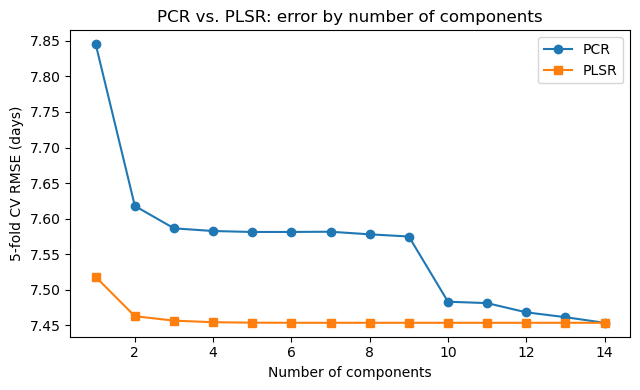

In [5]:
n_max = X.shape[1]
pcr_rmse, pls_rmse = [], []
for m in range(1, n_max + 1):
    pcr = make_pipeline(StandardScaler(), PCA(n_components=m), LinearRegression())
    pls = PLSRegression(n_components=m, scale=True)
    pcr_rmse.append(-cross_val_score(pcr, X_tr, y_tr, cv=cv, scoring='neg_root_mean_squared_error').mean())
    pls_rmse.append(-cross_val_score(pls, X_tr, y_tr, cv=cv, scoring='neg_root_mean_squared_error').mean())

comp = pd.DataFrame({'components': range(1, n_max + 1), 'PCR_cv_RMSE': pcr_rmse, 'PLS_cv_RMSE': pls_rmse})
print(comp.round(4).to_string(index=False))

pca_var = PCA().fit(StandardScaler().fit_transform(X_tr)).explained_variance_ratio_
print('\nVariance of X explained by first 3 PCs:', pca_var[:3].round(3), '| cumulative:', pca_var[:3].sum().round(3))

plt.figure(figsize=(6.5, 4))
plt.plot(comp['components'], comp['PCR_cv_RMSE'], 'o-', label='PCR')
plt.plot(comp['components'], comp['PLS_cv_RMSE'], 's-', label='PLSR')
plt.xlabel('Number of components'); plt.ylabel('5-fold CV RMSE (days)')
plt.title('PCR vs. PLSR: error by number of components'); plt.legend()
plt.tight_layout(); plt.show()

The two methods behave very differently. PLSR reaches nearly its best error with just 2 components, because it builds components that are directly related to mental health days. PCR needs 13–14 components to catch up. Its components capture the most variation in the features themselves (the first 3 explain only 38% of it), and those directions are mostly not the ones that predict mental health. In this dataset, compressing the predictors without looking at the outcome throws away useful signal.

In [6]:
def pick(col):
    return int(comp.loc[comp[col] <= comp[col].min() + 0.01, 'components'].min())
m_pcr, m_pls = pick('PCR_cv_RMSE'), pick('PLS_cv_RMSE')

final = {
    f'OLS (all {n_max})':        (LinearRegression(), list(X.columns)),
    f'Forward-selected ({k_sel})': (LinearRegression(), sel_feats),
    f'PCR ({m_pcr} comps)':       (make_pipeline(StandardScaler(), PCA(n_components=m_pcr), LinearRegression()), list(X.columns)),
    f'PLSR ({m_pls} comps)':      (PLSRegression(n_components=m_pls, scale=True), list(X.columns)),
}
rows = []
for name, (model, feats) in final.items():
    model.fit(X_tr[feats], y_tr)
    pred = np.ravel(model.predict(X_te[feats]))
    rows.append({'model': name, 'test_R2': r2_score(y_te, pred),
                 'test_RMSE': np.sqrt(mean_squared_error(y_te, pred))})
print(pd.DataFrame(rows).round(4).to_string(index=False))

               model  test_R2  test_RMSE
        OLS (all 14)   0.2011     7.5695
Forward-selected (8)   0.2000     7.5749
      PCR (13 comps)   0.1983     7.5829
      PLSR (2 comps)   0.1993     7.5781


On the test set, all four models land within 0.02 of each other in R² (0.198–0.201) and within 0.015 days in RMSE. The 8-feature model and the 2-component PLSR model match the full model with far less complexity. This confirms the Week 2 finding: a handful of factors, led by physical health, age and general health, drive what these variables can predict. Fewer features, or a couple of well-chosen components, lose almost nothing.